## Per-Slide Macenko Stain Normalization Reference (`A_qc-v5` & `B_qc-v5`)

### Overview
This notebook builds a validated **Macenko stain normalization reference** (`ref_stain` and `ref_max_c`) across whole-slide tile `.h5` files in `A_qc-v5` and `B_qc-v5` on `/Volumes/Expansion`[cite: 12], then verifies normalization quality visually.

### Key Fixes Applied
* **Per-Slide Estimation + Median Aggregation:** Estimates stain vectors per slide via SVD and polar angles in optical density (OD) space rather than pooling raw pixels globally, preventing collapsed/nearly identical stain vectors (which previously yielded `0.41°` separation and `ref_max_c ≈ 80`, making normalized tiles dark and uniform)[cite: 10].
* **HDF5 Byte-Encoded Tile Decoding:** Decodes 1D `object` (`tiles (N,)`) compressed image entries (`PNG`/`JPEG`/raw bytes) via `PIL` + `io.BytesIO` into `(H, W, 3)` `uint8` RGB arrays[cite: 17].
* **macOS External Drive & File Safety:** Ignores `._*` AppleDouble files, searches recursively with `rglob("*.h5")`, catches unreadable HDF5 `OSError`s per file, and avoids `StopIteration` when dataset keys/shapes vary[cite: 15, 16].

### Notebook Cells
1. **Config:** Paths (`A_qc-v5`, `B_qc-v5` under `/Volumes/Expansion/pathology_data/packages`)[cite: 12], sampling counts, OD thresholds, and angle/concentration checks.
2. **Core Functions:** Tile decoding, RGB $\leftrightarrow$ OD conversion, tissue pixel filtering, per-slide Macenko estimation, and tile normalization.
3. **Reference Builder & Validation:** Samples slides, validates stain angle and `ref_max_c`, and saves `macenko_reference_v2.npz`.
4. **Visual QC:** Side-by-side comparison of raw vs. Macenko-normalized tissue tiles.
5. **Cohort Check:** Compares stain matrices and concentration quantiles between `A_qc-v5` and `B_qc-v5`.


In [50]:
import io
from pathlib import Path
import random
import h5py
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

# Exact dataset paths on /Volumes/Expansion
DATA_DIRS = [
    Path("/Volumes/Expansion/pathology_data/packages/A_qc-v5"),
    Path("/Volumes/Expansion/pathology_data/packages/B_qc-v5"),
]
OUT_NPZ = Path("macenko_reference_v2.npz")

# Macenko & sampling parameters
SEED = 42
TILES_PER_SLIDE = 25          # Number of tiles sampled per .h5 slide
MAX_PIXELS_PER_SLIDE = 25_000 # Subsampled tissue OD pixels per slide for fast SVD
OD_BETA = 0.15                # Minimum OD L2 norm to exclude white background
OD_MAX = 3.0                  # Exclude extreme dark ink / debris artifacts
ALPHA_PCT = 1.0               # 1st and 99th percentile angles in stain plane
MIN_ANGLE_DEG = 5.0           # Reject slides with collapsed/collinear stain vectors
CONC_PCT = 99.0               # Concentration quantile for reference scaling

rng = np.random.default_rng(SEED)
random.seed(SEED)

In [51]:
def decode_tile_item(item) -> np.ndarray | None:
    """Decode a single HDF5 object/byte tile entry (PNG/JPEG/bytes/array) to (H, W, 3) uint8 RGB."""
    if item is None:
        return None
    if isinstance(item, np.ndarray):
        if item.ndim == 3 and item.shape[-1] == 3:
            return item.astype(np.uint8)
        raw_bytes = item.tobytes()
    elif isinstance(item, (bytes, bytearray, memoryview)):
        raw_bytes = bytes(item)
    else:
        raw_bytes = bytes(item)

    try:
        with Image.open(io.BytesIO(raw_bytes)) as im:
            return np.asarray(im.convert("RGB"), dtype=np.uint8)
    except Exception:
        return None


def rgb_to_od(rgb: np.ndarray) -> np.ndarray:
    """Convert uint8 RGB image (..., 3) to natural-log Optical Density."""
    rgb_f = np.clip(rgb.astype(np.float32), 0.0, 255.0)
    return -np.log((rgb_f + 1.0) / 256.0)


def od_to_rgb(od: np.ndarray) -> np.ndarray:
    """Convert Optical Density back to uint8 RGB."""
    rgb_f = np.exp(-np.clip(od, 0.0, 5.0)) * 256.0 - 1.0
    return np.clip(np.round(rgb_f), 0, 255).astype(np.uint8)


def extract_tissue_od(rgb: np.ndarray, beta: float = OD_BETA, od_max: float = OD_MAX) -> np.ndarray:
    """Flatten RGB tiles/images and keep valid non-background, non-artifact OD pixels."""
    od = rgb_to_od(rgb).reshape(-1, 3)
    norms = np.linalg.norm(od, axis=1)
    mask = (norms > beta) & (norms < od_max)
    return od[mask]


def estimate_slide_macenko(
    od: np.ndarray,
    alpha: float = ALPHA_PCT,
    min_angle_deg: float = MIN_ANGLE_DEG,
    conc_pct: float = CONC_PCT,
):
    """Estimate (2x3 stain_matrix, 2-element max_c) for a single slide's tissue OD pixels."""
    if len(od) < 200:
        return None, None

    # 1. Top-2 SVD directions span the stain plane
    _, _, vt = np.linalg.svd(od, full_matrices=False)
    plane_basis = vt[:2]  # (2, 3)

    # 2. Polar angles in the 2D stain plane (centered on circular mean to avoid +/- pi wrap splits)
    proj = od @ plane_basis.T
    angles = np.arctan2(proj[:, 1], proj[:, 0])
    center_angle = np.arctan2(np.sin(angles).mean(), np.cos(angles).mean())
    rel_angles = (angles - center_angle + np.pi) % (2 * np.pi) - np.pi

    low_ang = center_angle + np.percentile(rel_angles, alpha)
    high_ang = center_angle + np.percentile(rel_angles, 100.0 - alpha)

    v1 = np.array([np.cos(low_ang), np.sin(low_ang)]) @ plane_basis
    v2 = np.array([np.cos(high_ang), np.sin(high_ang)]) @ plane_basis

    v1 /= np.linalg.norm(v1) + 1e-8
    v2 /= np.linalg.norm(v2) + 1e-8

    # Ensure positive orientation in OD space
    if v1.sum() < 0:
        v1 = -v1
    if v2.sum() < 0:
        v2 = -v2

    # 3. Reject degenerate / nearly collinear stain fits
    cos_sim = np.clip(np.dot(v1, v2), -1.0, 1.0)
    angle_deg = np.degrees(np.arccos(cos_sim))
    if angle_deg < min_angle_deg:
        return None, None

    # 4. Consistent stain ordering: Hematoxylin (higher blue-channel OD) first, Eosin second
    if v1[2] < v2[2]:
        v1, v2 = v2, v1

    stain_matrix = np.vstack([v1, v2]).astype(np.float32)

    # 5. Compute concentrations & upper quantile
    conc = np.maximum(od @ np.linalg.pinv(stain_matrix), 0.0)
    max_c = np.percentile(conc, conc_pct, axis=0).astype(np.float32)

    if np.any(max_c <= 1e-6) or np.any(max_c > 50.0):
        return None, None

    return stain_matrix, max_c


def macenko_normalize_rgb(
    rgb: np.ndarray,
    ref_stain: np.ndarray,
    ref_max_c: np.ndarray,
    beta: float = OD_BETA,
    conc_pct: float = CONC_PCT,
    scale_bounds: tuple[float, float] = (0.5, 2.0),
) -> np.ndarray:
    """Normalize an RGB image (H, W, 3) using a validated Macenko reference."""
    orig_shape = rgb.shape
    od = rgb_to_od(rgb).reshape(-1, 3)
    norms = np.linalg.norm(od, axis=1)
    tissue_mask = norms > beta

    if tissue_mask.sum() < 50:
        return rgb.copy()

    od_tissue = od[tissue_mask]

    src_stain, src_max_c = estimate_slide_macenko(od_tissue, conc_pct=conc_pct)
    if src_stain is None:
        src_stain = ref_stain
        conc = np.maximum(od_tissue @ np.linalg.pinv(src_stain), 0.0)
        src_max_c = np.percentile(conc, conc_pct, axis=0)
    else:
        conc = np.maximum(od_tissue @ np.linalg.pinv(src_stain), 0.0)

    scale = ref_max_c / np.maximum(src_max_c, 1e-4)
    scale = np.clip(scale, scale_bounds[0], scale_bounds[1])
    conc_norm = conc * scale[None, :]

    od_norm = od.copy()
    od_norm[tissue_mask] = conc_norm @ ref_stain
    return od_to_rgb(od_norm).reshape(orig_shape)

In [52]:
def find_tile_dataset_key(f: h5py.File):
    """Find a suitable tile dataset key inside an open HDF5 file, or None."""
    for k in ("imgs", "tiles", "images"):
        if k in f and isinstance(f[k], h5py.Dataset):
            return k
    for k, v in f.items():
        if isinstance(v, h5py.Dataset) and v.ndim in (1, 3, 4):
            return k
    return None


def sample_slide_tiles(h5_path: Path, n_tiles: int = TILES_PER_SLIDE) -> list[np.ndarray]:
    """Sample decoded (H, W, 3) uint8 RGB tiles from an .h5 file (supports 4D or 1D object bytes)."""
    decoded_tiles = []
    with h5py.File(h5_path, "r") as f:
        img_key = find_tile_dataset_key(f)
        if img_key is None:
            return decoded_tiles

        ds = f[img_key]
        total = ds.shape[0] if len(ds.shape) > 0 else 0
        if total == 0:
            return decoded_tiles

        idx = np.sort(rng.choice(total, size=min(n_tiles, total), replace=False))

        if ds.ndim == 4:
            batch = ds[idx]
            for i in range(len(batch)):
                decoded_tiles.append(np.asarray(batch[i], dtype=np.uint8))
        elif ds.ndim == 1:
            for i in idx:
                img = decode_tile_item(ds[int(i)])
                if img is not None:
                    decoded_tiles.append(img)

    return decoded_tiles


def load_slide_tissue_od(h5_path: Path, n_tiles: int = TILES_PER_SLIDE) -> np.ndarray:
    """Sample tissue OD pixels from an .h5 tile container."""
    tiles = sample_slide_tiles(h5_path, n_tiles=n_tiles)
    if not tiles:
        return np.empty((0, 3), dtype=np.float32)

    od_parts = [extract_tissue_od(t) for t in tiles]
    od_parts = [p for p in od_parts if len(p) > 0]
    if not od_parts:
        return np.empty((0, 3), dtype=np.float32)

    od = np.vstack(od_parts)
    if len(od) > MAX_PIXELS_PER_SLIDE:
        sel = rng.choice(len(od), size=MAX_PIXELS_PER_SLIDE, replace=False)
        od = od[sel]
    return od


h5_files = sorted(
    p
    for d in DATA_DIRS
    if d.exists()
    for p in d.rglob("*.h5")
    if not p.name.startswith("._")
)
print(f"Found {len(h5_files)} candidate .h5 slide files across {[str(d) for d in DATA_DIRS]}.")

if len(h5_files) == 0:
    for d in DATA_DIRS:
        print(f"  {d} -> exists={d.exists()}, is_dir={d.is_dir()}")
    raise FileNotFoundError(
        "No .h5 files found. Check DATA_DIRS paths, /Volumes/Expansion mount status, or file extensions."
    )

slide_stains = []
slide_max_cs = []
valid_h5_files = []
bad_files = []

for h5_path in tqdm(h5_files, desc="Estimating per-slide Macenko"):
    try:
        od = load_slide_tissue_od(h5_path)
    except OSError as e:
        bad_files.append((str(h5_path), str(e)))
        continue

    stain_mat, max_c = estimate_slide_macenko(od)
    if stain_mat is not None:
        slide_stains.append(stain_mat)
        slide_max_cs.append(max_c)
        valid_h5_files.append(h5_path)

if bad_files:
    print(f"Skipped {len(bad_files)} unreadable/non-HDF5 files (first 5): {bad_files[:5]}")

if len(slide_stains) == 0:
    raise RuntimeError(
        "No slides produced a valid Macenko stain matrix. Check MIN_ANGLE_DEG, OD_BETA/OD_MAX, or tile decoding."
    )

slide_stains = np.stack(slide_stains, axis=0)  # (N_valid, 2, 3)
slide_max_cs = np.stack(slide_max_cs, axis=0)  # (N_valid, 2)

# Median aggregation across valid slides + re-normalization to unit vectors
ref_stain = np.median(slide_stains, axis=0)
ref_stain /= np.linalg.norm(ref_stain, axis=1, keepdims=True)
ref_max_c = np.median(slide_max_cs, axis=0)

# Sanity checks
cos_sim = np.dot(ref_stain[0], ref_stain[1])
angle_deg = np.degrees(np.arccos(np.clip(cos_sim, -1.0, 1.0)))
cond_num = np.linalg.cond(ref_stain)

print(f"\nValid slides used: {len(slide_stains)} / {len(h5_files)}")
print(f"Angle between stain vectors: {angle_deg:.2f} deg (healthy H&E is ~25–60 deg)")
print(f"Condition number: {cond_num:.2f}")
print(f"ref_stain:\n{ref_stain}")
print(f"ref_max_c: {ref_max_c}")

assert angle_deg >= MIN_ANGLE_DEG, f"Stain vectors collapsed ({angle_deg:.2f} deg)!"
assert 0.1 < ref_max_c.min() and ref_max_c.max() < 20.0, f"Unexpected ref_max_c: {ref_max_c}"

np.savez(
    OUT_NPZ,
    ref_stain=ref_stain,
    ref_max_c=ref_max_c,
    slide_stains=slide_stains,
    slide_max_cs=slide_max_cs,
)
print(f"Saved validated reference to {OUT_NPZ}")

Found 521 candidate .h5 slide files across ['/Volumes/Expansion/pathology_data/packages/A_qc-v5', '/Volumes/Expansion/pathology_data/packages/B_qc-v5'].


Estimating per-slide Macenko:   0%|          | 0/521 [00:00<?, ?it/s]


Valid slides used: 521 / 521
Angle between stain vectors: 30.09 deg (healthy H&E is ~25–60 deg)
Condition number: 3.72
ref_stain:
[[0.09139168 0.79628104 0.5979833 ]
 [0.5545558  0.74586546 0.3689887 ]]
ref_max_c: [1.6155608 2.1330426]
Saved validated reference to macenko_reference_v2.npz


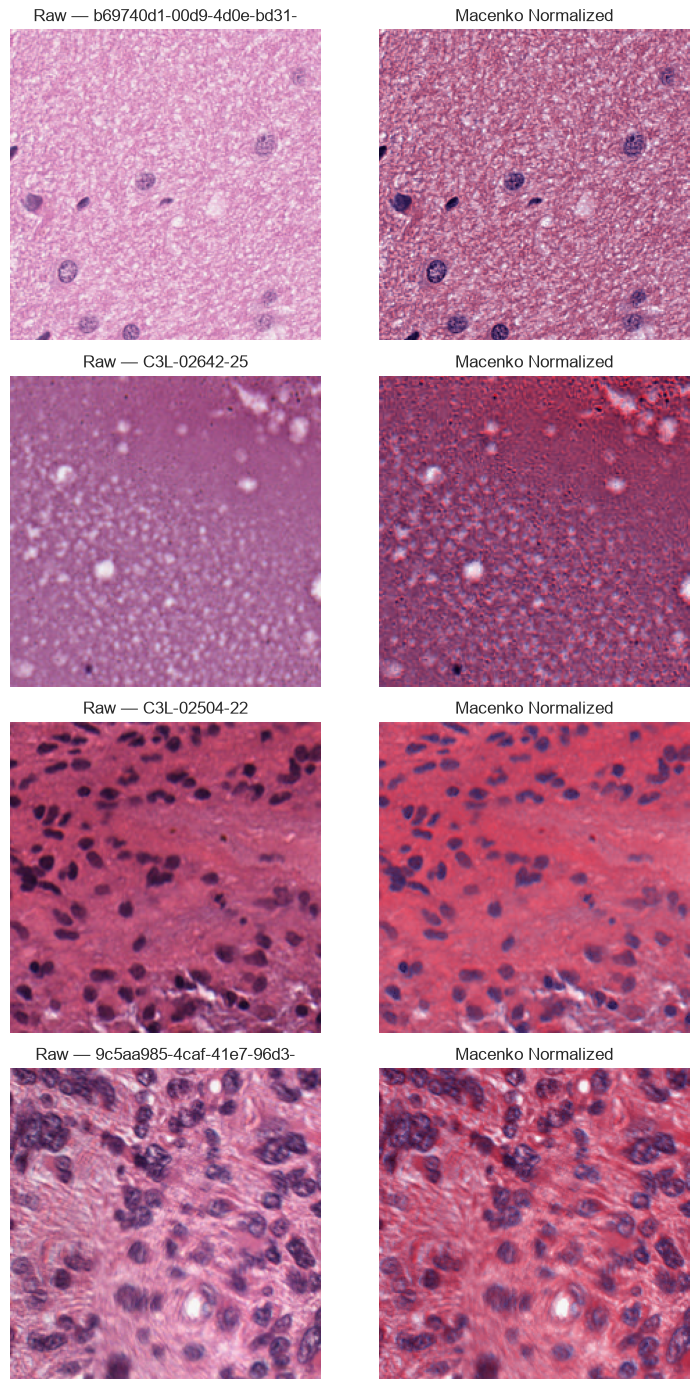

In [53]:
ref = np.load(OUT_NPZ)
ref_stain = ref["ref_stain"]
ref_max_c = ref["ref_max_c"]

pool_files = valid_h5_files if "valid_h5_files" in globals() and len(valid_h5_files) > 0 else h5_files
sample_files = random.sample(pool_files, k=min(4, len(pool_files)))

fig, axes = plt.subplots(len(sample_files), 2, figsize=(8, 3.5 * len(sample_files)))
if len(sample_files) == 1:
    axes = axes[None, :]

for row, h5_path in enumerate(sample_files):
    candidates = sample_slide_tiles(h5_path, n_tiles=20)
    tissue_scores = [extract_tissue_od(t).shape[0] for t in candidates]
    raw_tile = candidates[int(np.argmax(tissue_scores))]

    norm_tile = macenko_normalize_rgb(raw_tile, ref_stain, ref_max_c)

    axes[row, 0].imshow(raw_tile)
    axes[row, 0].set_title(f"Raw — {h5_path.stem[:24]}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(norm_tile)
    axes[row, 1].set_title("Macenko Normalized")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [54]:
cohort_summary = {}
for d in DATA_DIRS:
    if not d.exists():
        print(f"Skipping {d} (does not exist)")
        continue
    stains, cs, skipped = [], [], 0
    for p in sorted(d.rglob("*.h5"))[:60]:
        if p.name.startswith("._"):
            continue
        try:
            od = load_slide_tissue_od(p, n_tiles=15)
        except OSError:
            skipped += 1
            continue
        s, c = estimate_slide_macenko(od)
        if s is not None:
            stains.append(s)
            cs.append(c)
    if stains:
        med_s = np.median(stains, axis=0)
        med_s /= np.linalg.norm(med_s, axis=1, keepdims=True)
        cohort_summary[d.name] = (med_s, np.median(cs, axis=0))
        print(f"{d.name} (n={len(stains)}, skipped={skipped}): max_c={cohort_summary[d.name][1].round(3)}")
        print(cohort_summary[d.name][0].round(4), "\n")

A_qc-v5 (n=29, skipped=0): max_c=[1.686 2.184]
[[0.1149 0.8083 0.5775]
 [0.6014 0.7203 0.3458]] 

B_qc-v5 (n=60, skipped=0): max_c=[1.515 2.155]
[[0.0764 0.7735 0.6292]
 [0.5463 0.7522 0.3685]] 



=== Reference Comparison (rows = [Stain 0, Stain 1], cols = [R, G, B]) ===
global_reference         | angle=30.09 deg | max_c=[1.6156 2.133 ]
[[0.0914 0.7963 0.598 ]
 [0.5546 0.7459 0.369 ]]

cohort_all_start (hardcoded) | angle=25.41 deg | max_c=[3.1147 2.4863]
[[0.5552 0.7381 0.3834]
 [0.1618 0.8073 0.5676]]

Row cosine similarity: stain0=0.8677, stain1=0.9013
max_c diff (mine - cohort_all_start): [-1.4992 -0.3532]


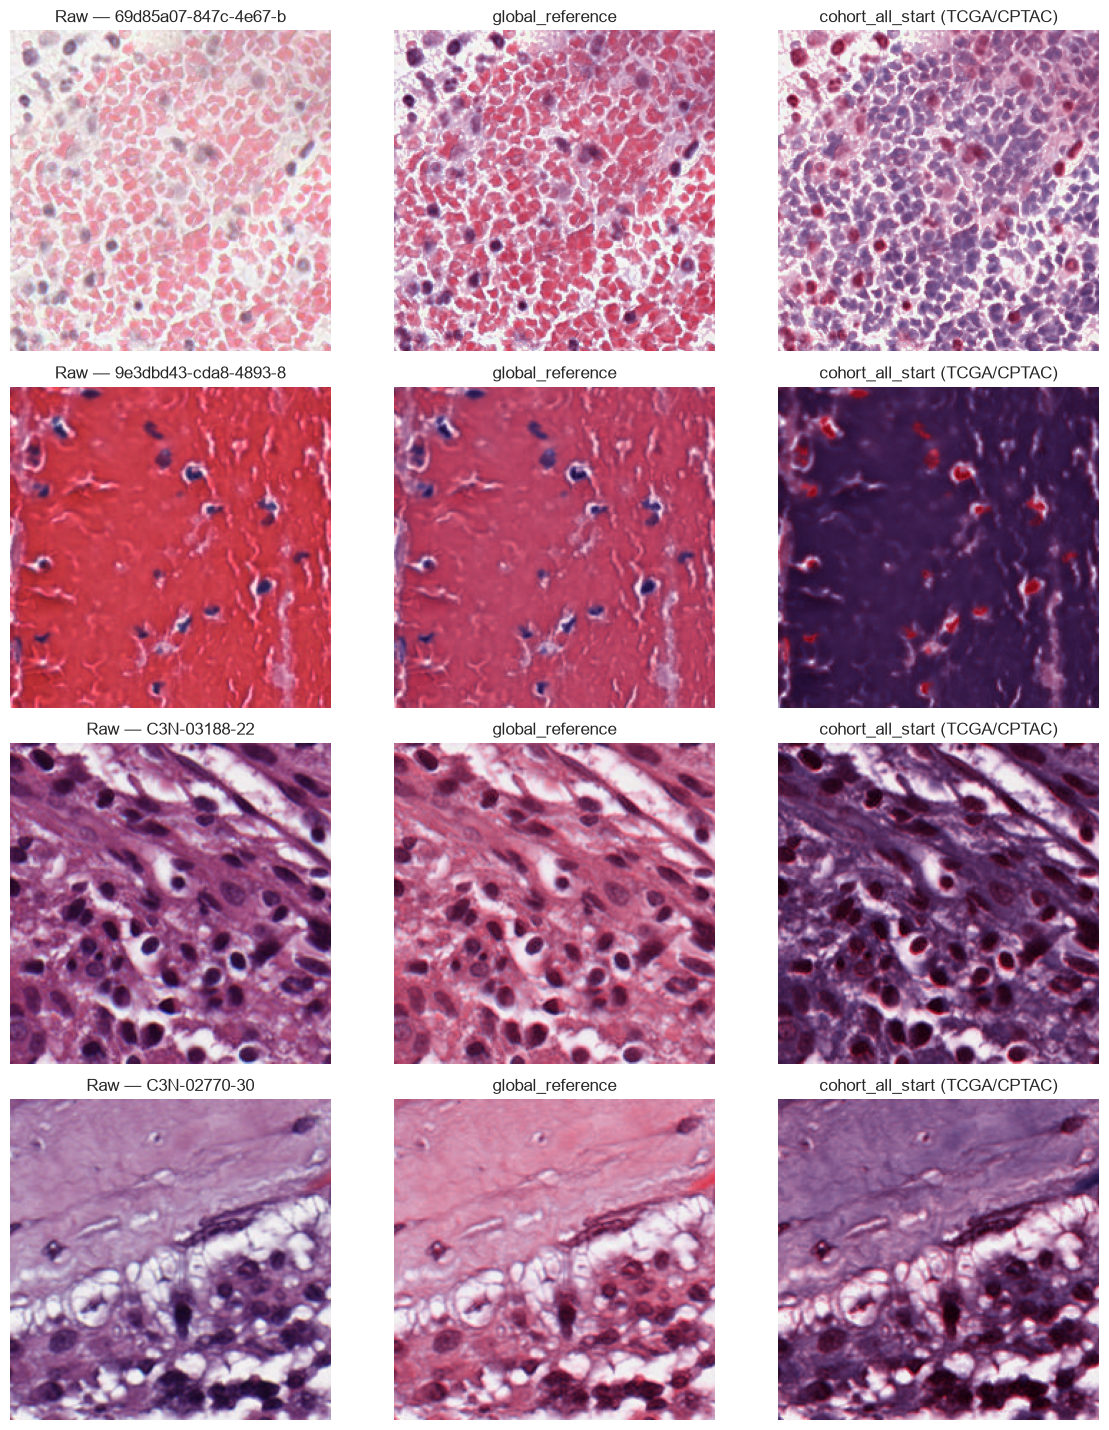

In [55]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Hardcoded cohort_all_start (TCGA / CPTAC) Reference ---
COHORT_ALL_START = {
    "sources": ["TCGA", "CPTAC"],
    "seed": 0,
    "per_patient": 100,
    "patients": 232,
    "tiles_used": 23161,
    "tiles_failed": 0,
    "tissue_pixels": 11580500,
    "stain_std_across_tiles": [
        [0.07334772750887712, 0.04292965001309276, 0.05102151796563989],
        [0.08945726451914102, 0.07782669425893597, 0.11234761620930273],
    ],
    "modeling_sha256": (
        "51663e49c912243a946fa06fa7b0478996e91ea8f76c673a4aef65d50bf0c8a0"
    ),
    "ref_HE": [
        [0.5551982522010803, 0.1618349552154541],
        [0.7380538582801819, 0.8072702288627625],
        [0.3834467828273773, 0.5675598978996277],
    ],
    "ref_max_C": [3.1147451400756836, 2.486283540725708],
    "npz_sha256": (
        "d55ae8d0bb0b5ef0ee276be95af16ddf4eb6abc064219a84e52c05b076b40bea"
    ),
}


def to_2x3_unit(stain_arr: np.ndarray) -> np.ndarray:
  arr = np.asarray(stain_arr, dtype=np.float32)
  stain_2x3 = arr.T if arr.shape == (3, 2) else arr
  return stain_2x3 / (np.linalg.norm(stain_2x3, axis=1, keepdims=True) + 1e-8)


def stain_angle_deg(stain_2x3: np.ndarray) -> float:
  v0, v1 = stain_2x3[0], stain_2x3[1]
  cos_sim = np.clip(
      np.dot(v0, v1) / ((np.linalg.norm(v0) * np.linalg.norm(v1)) + 1e-8),
      -1.0,
      1.0,
  )
  return float(np.degrees(np.arccos(cos_sim)))


def normalize_with_2x3(
    rgb: np.ndarray,
    stain_2x3: np.ndarray,
    max_c: np.ndarray,
    beta: float = OD_BETA,
    conc_pct: float = CONC_PCT,
    scale_bounds: tuple[float, float] = (0.5, 2.0),
) -> np.ndarray:
  orig_shape = rgb.shape
  od = rgb_to_od(rgb).reshape(-1, 3)
  tissue_mask = np.linalg.norm(od, axis=1) > beta
  if tissue_mask.sum() < 50:
    return rgb.copy()

  od_tissue = od[tissue_mask]
  src_stain, src_max_c = estimate_slide_macenko(od_tissue, conc_pct=conc_pct)
  if src_stain is None:
    src_stain = stain_2x3
    conc = np.maximum(od_tissue @ np.linalg.pinv(src_stain), 0.0)
    src_max_c = np.percentile(conc, conc_pct, axis=0)
  else:
    conc = np.maximum(od_tissue @ np.linalg.pinv(src_stain), 0.0)

  scale = np.clip(
      max_c / np.maximum(src_max_c, 1e-4), scale_bounds[0], scale_bounds[1]
  )
  od_norm = od.copy()
  od_norm[tissue_mask] = (conc * scale[None, :]) @ stain_2x3
  return od_to_rgb(od_norm).reshape(orig_shape)


# --- 2. Load Your global_reference from Memory or Disk ---
if "ref_stain" in globals() and "ref_max_c" in globals():
  my_stain = to_2x3_unit(ref_stain)
  my_max_c = np.asarray(ref_max_c, dtype=np.float32)
elif Path("global_reference.npz").exists():
  g = np.load("global_reference.npz")
  raw_s = g["ref_HE"] if "ref_HE" in g else g["ref_stain"]
  my_stain = to_2x3_unit(raw_s)
  my_max_c = np.asarray(
      g["ref_max_C"] if "ref_max_C" in g else g["ref_max_c"], dtype=np.float32
  )
elif Path("macenko_reference_v2.npz").exists():
  g = np.load("macenko_reference_v2.npz")
  my_stain = to_2x3_unit(g["ref_stain"])
  my_max_c = np.asarray(g["ref_max_c"], dtype=np.float32)
else:
  raise RuntimeError(
      "Run Cell 3 first so ref_stain and ref_max_c are available in memory."
  )

tcga_stain = to_2x3_unit(COHORT_ALL_START["ref_HE"])
tcga_max_c = np.asarray(COHORT_ALL_START["ref_max_C"], dtype=np.float32)

# --- 3. Print Comparison ---
print("=== Reference Comparison (rows = [Stain 0, Stain 1], cols = [R, G, B]) ===")
print(
    f"global_reference         | angle={stain_angle_deg(my_stain):.2f} deg |"
    f" max_c={my_max_c.round(4)}"
)
print(my_stain.round(4))
print(
    f"\ncohort_all_start (hardcoded) | angle={stain_angle_deg(tcga_stain):.2f}"
    f" deg | max_c={tcga_max_c.round(4)}"
)
print(tcga_stain.round(4))

row_cos = [float(np.dot(my_stain[i], tcga_stain[i])) for i in range(2)]
print(
    f"\nRow cosine similarity: stain0={row_cos[0]:.4f}, stain1={row_cos[1]:.4f}"
)
print(f"max_c diff (mine - cohort_all_start): {(my_max_c - tcga_max_c).round(4)}")

# --- 4. Visualize Raw vs global_reference vs cohort_all_start ---
tile_pool = (
    valid_h5_files
    if "valid_h5_files" in globals() and len(valid_h5_files) > 0
    else h5_files
)
n_samples = min(4, len(tile_pool))
sample_paths = random.sample(tile_pool, k=n_samples)

fig, axes = plt.subplots(n_samples, 3, figsize=(12, 3.6 * n_samples))
if n_samples == 1:
  axes = axes[None, :]

for row, h5_path in enumerate(sample_paths):
  candidates = sample_slide_tiles(h5_path, n_tiles=20)
  scores = [extract_tissue_od(t).shape[0] for t in candidates]
  raw_tile = candidates[int(np.argmax(scores))]

  norm_mine = normalize_with_2x3(raw_tile, my_stain, my_max_c)
  norm_tcga = normalize_with_2x3(raw_tile, tcga_stain, tcga_max_c)

  axes[row, 0].imshow(raw_tile)
  axes[row, 0].set_title(f"Raw — {h5_path.stem[:20]}")
  axes[row, 0].axis("off")

  axes[row, 1].imshow(norm_mine)
  axes[row, 1].set_title("global_reference")
  axes[row, 1].axis("off")

  axes[row, 2].imshow(norm_tcga)
  axes[row, 2].set_title("cohort_all_start (TCGA/CPTAC)")
  axes[row, 2].axis("off")

plt.tight_layout()
plt.show()